# **Геомаркетинговое исследование территорий с применением современных методов машинного обучения**


## **Введение**

В данном блокноте мы применим методы геоанализа и машинного обучения для решения практической задачи: определения оптимальных локаций для открытия нового фитнес-центра. Мы соберем, обработаем и проанализируем пространственные данные, обучим модели машинного обучения и визуализируем результаты для принятия обоснованных бизнес-решений.



**В рамках данного блокнота мы:**

*   Произведем сбор геоданных из открытых источников (OpenStreetMap).
*   Вновь поработаем с гексагональными сетками (H3) для агрегации данных.
*   Поймем принципы Feature Engineering для пространственных данных.
*   Применим модели машинного обучения для оценки привлекательности локаций.
*   Разработаем методику расчета итогового потенциала с учетом конкуренции.
*   Визуализируем результаты анализа на интерактивной карте.

## **Раздел 1. Подготовка среды и сбор пространственных данных**





### **1.1. Необходимые инструменты и библиотеки**

Для выполнения анализа нам потребуется ряд специализированных Python-библиотек:

*   `geopandas`: Расширение Pandas для работы с геопространственными данными. Позволяет читать, записывать и манипулировать векторными данными (точки, линии, полигоны).
*   `osmnx`: Библиотека для загрузки данных из OpenStreetMap, включая объекты инфраструктуры и дорожные графы.
*   `h3`: Библиотека для работы с гексагональной сеткой H3.
*   `shapely`: Библиотека для манипуляций и анализа геометрических объектов.
*   `scikit-learn`: Основная библиотека для машинного обучения в Python. Содержит реализации алгоритмов (Random Forest, KMeans), метрик качества и инструментов предобработки (StandardScaler).
*   `leafmap` / `ipyleaflet`: Библиотеки для создания интерактивных карт непосредственно в среде Jupyter Notebook/Colab.
*   `pandas`, `numpy`: Стандартные библиотеки для работы с данными и вычислениями.
*   `matplotlib`, `seaborn`: Библиотеки для статической визуализации данных.
*   `kneed`: Для автоматического определения "локтя" на графике (используется при выборе числа кластеров).

### **1.2. Установка зависимостей**








Первым шагом установим все необходимые библиотеки. Команда `%%capture` подавляет вывод процесса установки. Флаг `-q` (quiet) также уменьшает количество выводимой информации.

In [ ]:
%%capture
!pip install scikit-learn geopandas h3pandas h3~=3.0 leafmap mapclassify matplotlib streamlit osmnx kneed openrouteservice polyline -q

In [ ]:
# Импортируем основные библиотеки
import geopandas as gpd
import pandas as pd
import numpy as np
import h3 # Библиотека для работы с H3-индексами
from shapely.geometry import box, Polygon # Для создания геометрических объектов
import osmnx as ox # Для загрузки данных из OpenStreetMap
from sklearn.preprocessing import StandardScaler # Для масштабирования признаков
from sklearn.cluster import KMeans, MiniBatchKMeans # Алгоритмы кластеризации
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier # Модели машинного обучения
from sklearn.metrics import silhouette_score, roc_auc_score, accuracy_score, classification_report # Метрики качества
from sklearn.model_selection import train_test_split, cross_val_score # Для разделения данных и кросс-валидации
from sklearn.decomposition import PCA
from sklearn.preprocessing import OneHotEncoder
import leafmap.leafmap as leafmap # Для интерактивных карт
from ipywidgets import HTML # Для форматирования текста во всплывающих окнах карты
from ipyleaflet import AwesomeIcon, Marker, MarkerCluster # Для кастомизации маркеров на карте
import warnings
import matplotlib.pyplot as plt # Для графиков
import seaborn as sns # Для улучшенных графиков
from kneed import KneeLocator # Для автоматизации определения кол-ва кластеров


# Игнорировать предупреждения о будущих изменениях в библиотеках для чистоты вывода
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=UserWarning) # Игнорировать предупреждения от OSMnx/sklearn

### **1.3. Источники геоданных (OpenStreetMap) и выбор области интереса (ROI)**

**OpenStreetMap (OSM)** – это краудсорсинговый проект, предоставляющий бесплатные и открытые геоданные по всему миру. Данные хранятся в виде объектов (узлы, пути, отношения) с набором тегов (ключ=значение), описывающих их характеристики (например, `amenity=cafe`, `building=office`). Библиотека `osmnx` позволяет легко запрашивать и загружать эти данные для определенной территории.

**Область интереса (Region of Interest, ROI)** – это географическая область, в пределах которой будет проводиться анализ. Обычно задается с помощью **ограничивающего прямоугольника (Bounding Box, bbox)**, который определяется координатами его углов (минимальная долгота, минимальная широта, максимальная долгота, максимальная широта). Выбор правильного ROI критичен: слишком маленькая область может не дать репрезентативных результатов, а слишком большая – привести к излишним вычислениям и затратам времени/ресурсов.



### **1.4. Определение ROI и загрузка данных (фитнес-центров, инфраструктура)**



Сначала создадим интерактивную карту, на которой можно вручную нарисовать прямоугольник, определяющий наш ROI. Если прямоугольник не нарисован, будут использованы координаты по умолчанию (в данном случае, часть Москвы).

In [ ]:
# Создаем интерактивную карту с центром в Москве
m = leafmap.Map(center=[55.751244, 37.618423], zoom=10)
m # Отображаем карту

Map(center=[55.751244, 37.618423], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title',…

*Инструкция:* На отобразившейся карте используйте инструмент "Нарисовать прямоугольник" (квадратная иконка на панели слева), чтобы выделить интересующую вас область. Затем выполните следующую ячейку кода.

In [ ]:
# Получаем координаты нарисованного прямоугольника (bounding box)
bbox = m.user_roi_bounds()

# Если ROI не был нарисован, используем bbox по умолчанию (центр Москвы)
if bbox:
    print(f"Выбранный bounding box: {bbox}")
else:
    # Пример bbox для части Москвы (запад, юг, восток, север)
    bbox = [37.5033, 55.6904, 37.7519, 55.8051]
    print(f"Используется bounding box по умолчанию: {bbox}")

Выбранный bounding box: [37.4208, 55.6047, 37.8424, 55.8699]


In [ ]:
# --- Параметры анализа ---
# Разрешение сетки H3 (меньше значение = крупнее гексагоны)
# 10 (~150м сторона), 11 (~58м сторона), 12 (~22м сторона)
h3_resolution = 9 # Выбрано разрешение 9 (~350м сторона гексагона)

# Радиусы анализа (в метрах) для Feature Engineering
near_radius = 150  # Ближайшее окружение (2-3 минуты пешком)
medium_radius = 400 # Среднее окружение (5-7 минут пешком)


target_crs = "EPSG:3857"

In [ ]:
print("Шаг 1: Загрузка данных о существующих фитнес-центрах...")
# Теги для поиска фитнес-центров в OSM
fitness_tags = {'leisure': 'fitness_centre', 'amenity': 'gym', 'sport': 'fitness'}
try:
    # Получаем геометрии из OSM в пределах bbox
    west, south, east, north = bbox
    fitness_centers = ox.features_from_bbox((west, south, east, north), tags=fitness_tags)
    # Фильтруем только точки и полигоны (иногда попадаются линии)
    fitness_centers = fitness_centers[fitness_centers.geometry.type.isin(['Point', 'Polygon'])]
    if not fitness_centers.empty:
        print(f"Найдено {len(fitness_centers)} фитнес-центров в указанной области")
    else:
        print("В указанной области не найдено фитнес-центров")
        fitness_centers = gpd.GeoDataFrame(geometry=[], crs="EPSG:4326")
except Exception as e:
    print(f"Ошибка при получении данных о фитнес-центрах: {e}")
    fitness_centers = gpd.GeoDataFrame(geometry=[], crs="EPSG:4326")

Шаг 1: Загрузка данных о существующих фитнес-центрах...
Найдено 1623 фитнес-центров в указанной области


In [ ]:
# --- Шаг 2: Загрузка данных об основных объектах инфраструктуры (Конструктивные признаки) ---

# Словарь с категориями объектов и соответствующими тегами в OSM.
# Эти объекты будут использоваться для создания признаков локаций.
factor_tags = {
    # Места притяжения людей (работа, учеба)
    'offices': {'building': 'office'}, # Офисные здания
    'education': {'amenity': ['university', 'school', 'college']}, # Учебные заведения
    # Торговля и услуги (синергия, трафик)
    'retail': {'shop': True}, # Все магазины
    'services': {'amenity': ['bank', 'post_office', 'pharmacy']}, # Банки, почта, аптеки
    'food_other': {'amenity': ['restaurant', 'fast_food', 'pub', 'bar']}, # Другие точки питания (конкуренты/синергия)
    # Транспортная доступность
    'transport_stops': {'public_transport': 'stop_position', 'highway': 'bus_stop'}, # Остановки ОТ
    'transport_hubs': {'railway': ['station', 'subway_entrance'], 'amenity': 'bus_station'}, # Вокзалы, входы в метро
    'parking': {'amenity': 'parking'}, # Парковки
    # Жилые зоны (вечерние/выходные клиенты)
    'residential': {'building': ['apartments', 'residential', 'house']}, # Жилые дома
    # Отдых и досуг (свободное время, туристы)
    'parks': {'leisure': ['park', 'garden', 'square', 'playground']}, # Парки, скверы, площадки
    'tourism': {'tourism': ['hotel', 'guest_house', 'hostel', 'museum', 'attraction']}, # Гостиницы, музеи
    'culture': {'amenity': ['theatre', 'cinema', 'library', 'arts_centre']}, # Культурные объекты
    'fitness': {'leisure': 'fitness_centre', 'sport': 'fitness'}, # Фитнес-центры
    # Пешеходная инфраструктура
    'pedestrian_zones': {'highway': 'pedestrian'}, # Пешеходные улицы/зоны (часто полигоны)
    'footways': {'highway': ['footway', 'path', 'steps']}, # Тротуары, дорожки (линии)
    # Дорожная сеть (для анализа длины дорог)
    'roads': {'highway': ['primary', 'secondary', 'tertiary', 'residential', 'living_street', 'unclassified']} # Основные типы дорог
}


In [ ]:
print("\nШаг 2: Загрузка данных об основных объектах инфраструктуры...")
# Собираем данные для каждой категории объектов
factors_data = {}
# Используем общий граф дорог для экономии запросов, если нужны дороги/пешеходные пути
graph_proj = None
for factor_name, tags in factor_tags.items():
    print(f"  Загрузка данных: {factor_name}...")
    try:
        if factor_name in ['roads', 'footways', 'pedestrian_zones']:
             # Загружаем граф один раз, если еще не загружен
             if graph_proj is None:
                 print("    Загрузка графа дорог...")
                 graph = ox.graph_from_bbox((west, south, east, north))
                 graph_proj = ox.project_graph(graph) # Проецируем для метрических расчетов
                 print("    Граф дорог загружен и спроецирован.")

             # Получаем ребра (дороги/пути) из графа
             gdf = ox.graph_to_gdfs(graph_proj, nodes=False, edges=True)
             # Фильтруем по нужным типам highway
             if factor_name == 'roads':
                 valid_road_types = tags.get('highway', [])
                 gdf = gdf[gdf['highway'].apply(lambda x: x in valid_road_types if isinstance(x, str) else any(t in valid_road_types for t in x) if isinstance(x, list) else False)]
             elif factor_name == 'footways':
                 valid_foot_types = tags.get('highway', [])
                 gdf = gdf[gdf['highway'].apply(lambda x: x in valid_foot_types if isinstance(x, str) else any(t in valid_foot_types for t in x) if isinstance(x, list) else False)]
             elif factor_name == 'pedestrian_zones': # Пешеходные зоны часто как полигоны, но могут быть и линии
                 # Попробуем загрузить и полигоны отдельно
                 try:
                     gdf_poly = ox.features_from_bbox((west, south, east, north), tags={'highway': 'pedestrian'})
                     gdf_poly = gdf_poly[gdf_poly.geometry.type == 'Polygon'].to_crs(graph_proj.graph['crs'])
                     # Если есть и линии и полигоны, можно их объединить или обрабатывать отдельно
                     # Пока оставим только полигоны для 'pedestrian_zones' для расчета площади
                     gdf = gdf_poly
                 except Exception:
                     print(f"    Не удалось загрузить полигоны для {factor_name}, используем линии из графа (если есть).")
                     valid_ped_types = tags.get('highway', [])
                     gdf = gdf[gdf['highway'].apply(lambda x: x in valid_ped_types if isinstance(x, str) else any(t in valid_ped_types for t in x) if isinstance(x, list) else False)]

        else:
            # Для остальных объектов используем features_from_bbox
            gdf = ox.features_from_bbox((west, south, east, north), tags=tags)
            gdf = gdf[gdf.geometry.type.isin(['Point', 'Polygon'])] # Оставляем точки и полигоны
            gdf = gdf.to_crs(epsg=3857) # Проекция для метрических расчетов

        if not gdf.empty:
            # Убедимся, что CRS установлен правильно после всех операций
            if gdf.crs is None:
                 gdf.crs = "EPSG:3857" # Принудительно ставим, если потерялся
            elif gdf.crs != "EPSG:3857":
                 gdf = gdf.to_crs("EPSG:3857")

            factors_data[factor_name] = gdf
            print(f"    Найдено {len(gdf)} объектов")
        else:
            factors_data[factor_name] = gpd.GeoDataFrame(geometry=[], crs="EPSG:3857")
            print("    Объекты не найдены")
    except Exception as e:
        print(f"    Ошибка при загрузке {factor_name}: {e}")
        import traceback
        traceback.print_exc() # Печатаем traceback для детальной диагностики
        factors_data[factor_name] = gpd.GeoDataFrame(geometry=[], crs="EPSG:3857")

# Перепроецируем кофейни в ту же CRS для корреектных расчетов расстояний
if not fitness_centers.empty:
    fitness_centers_proj = fitness_centers.to_crs("EPSG:3857")
else:
    fitness_centers_proj = gpd.GeoDataFrame(geometry=[], crs="EPSG:3857")


Шаг 2: Загрузка данных об основных объектах инфраструктуры...
  Загрузка данных: offices...
    Найдено 4752 объектов
  Загрузка данных: education...
    Найдено 2055 объектов
  Загрузка данных: retail...
    Найдено 39367 объектов
  Загрузка данных: services...
    Найдено 5783 объектов
  Загрузка данных: food_other...
    Найдено 6998 объектов
  Загрузка данных: transport_stops...
    Найдено 16898 объектов
  Загрузка данных: transport_hubs...
    Найдено 1300 объектов
  Загрузка данных: parking...
    Найдено 14889 объектов
  Загрузка данных: residential...
    Найдено 27163 объектов
  Загрузка данных: parks...
    Найдено 12522 объектов
  Загрузка данных: tourism...
    Найдено 1907 объектов
  Загрузка данных: culture...
    Найдено 811 объектов
  Загрузка данных: fitness...
    Найдено 1619 объектов
  Загрузка данных: pedestrian_zones...
    Загрузка графа дорог...
    Граф дорог загружен и спроецирован.
    Найдено 192 объектов
  Загрузка данных: footways...
    Найдено 638693 о

### **1.5. Пояснение**



*   Мы определили область интереса (ROI) либо вручную, либо используя значения по умолчанию.
*   С помощью `osmnx` и заданных тегов мы загрузили два основных набора данных из OpenStreetMap:
    1.  **Существующие фитнес-центры:** Они будут использоваться для определения фактора конкуренции и как целевая переменная для моделирования привлекательности места расположения (предполагаем, что фитнес-центры чаще открываются в привлекательных местах).
    2.  **Объекты инфраструктуры:** Различные типы объектов (офисы, магазины, остановки, парки и т.д.), которые могут влиять на привлекательность локации для фитнес-центра. Они станут основой для создания признаков.
*   Важным шагом является **проецирование** всех геоданных в единую **метрическую систему координат** (например, UTM или Web Mercator EPSG:3857). Это необходимо для корректного расчета расстояний, площадей и длин в метрах (а не в градусах). Мы использовали CRS загруженного графа дорог для единообразия или EPSG:3857 по умолчанию.
*   Обработка ошибок (`try-except`) важна, так как загрузка данных из OSM может завершиться неудачно (например, из-за проблем с сетью или отсутствия данных). Создание пустых GeoDataFrame позволяет коду выполняться дальше без сбоев.




**Вывод по разделу:** На этом этапе мы собрали "сырые" геоданные, необходимые для дальнейшего анализа. Качество и полнота этих данных напрямую влияют на итоговый результат.

## **Раздел 2. Определение территориальной единицы и инженерия пространственных признаков (Feature Engineering)**


### **2.1. Гексагональные сетки H3 для агрегации данных**


Чтобы анализировать территорию не по отдельным объектам, а по небольшим зонам, удобно использовать **пространственную сетку**. Вместо традиционной квадратной сетки мы будем использовать **гексагональную сетку H3**.

Преимущества гексагонов:

*   Все соседи ячейки находятся примерно на одинаковом расстоянии от ее центра.
*   Они лучше аппроксимируют круговые области (например, зоны пешей доступности).
*   Меньше искажений формы и площади по сравнению с квадратами при проекциях.

**Разрешение H3 (h3\_resolution)** определяет размер ячеек: чем меньше значение, тем крупнее гексагоны. Мы выбрали разрешение `9`, что соответствует гексагонам со стороной около 350 метров – разумный масштаб для анализа локаций под фитнес-центр.





### **2.2. Код: Создание сетки H3**

Сгенерируем H3-ячейки, покрывающие наш ROI, и преобразуем их в GeoDataFrame.

In [ ]:
# --- Шаг 3: Создание гексагональной сетки H3 ---
print("\nШаг 3: Создание гексагональной сетки H3...")

# Создаем полигон из bbox (в исходной системе координат WGS84, т.к. h3 работает с lat/lon)
bbox_polygon = box(bbox[0], bbox[1], bbox[2], bbox[3]) # (min_lon, min_lat, max_lon, max_lat)

# Генерируем H3-индексы (строковые идентификаторы ячеек), полностью покрывающие полигон bbox
# h3.polyfill_geojson требует GeoJSON-подобный формат
h3_indexes = list(h3.polyfill_geojson(bbox_polygon.__geo_interface__, h3_resolution))
print(f"  Создано {len(h3_indexes)} гексагональных ячеек с разрешением {h3_resolution}")

# Преобразуем H3-индексы в геометрию полигонов
h3_polygons = []
for h3_idx in h3_indexes:
    # h3.h3_to_geo_boundary возвращает кортеж кортежей (lat, lon)
    h3_boundary_coords = h3.h3_to_geo_boundary(h3_idx, geo_json=False)
    # Преобразуем в формат (lon, lat) для создания объекта Polygon из библиотеки Shapely
    polygon_coords = [(lon, lat) for lat, lon in h3_boundary_coords]
    polygon = Polygon(polygon_coords)
    h3_polygons.append({'h3_index': h3_idx, 'geometry': polygon})

# Создаем GeoDataFrame с ячейками H3 в системе координат WGS84 (EPSG:4326)
h3_gdf = gpd.GeoDataFrame(h3_polygons, crs="EPSG:4326")

# Переводим сетку в ту же метрическую проекцию, что и остальные данные (target_crs определена ранее)
h3_gdf = h3_gdf.to_crs(target_crs)
print(f"  GeoDataFrame с ячейками H3 создан и спроецирован в {target_crs}")


Шаг 3: Создание гексагональной сетки H3...
  Создано 7886 гексагональных ячеек с разрешением 9
  GeoDataFrame с ячейками H3 создан и спроецирован в EPSG:3857


### **2.3. Создание признаков (Feature Engineering) на основе пространственных данных**



Теперь наша задача – для каждой ячейки H3 рассчитать набор **признаков**, характеризующих ее окружение. Этот процесс называется инженерией признаков (**Feature Engineering**). Мы будем использовать данные об инфраструктуре, загруженные на предыдущем шаге.

Основные методы:

*   **Пространственное пересечение (Intersection):** Определяем, какие объекты инфраструктуры попадают внутрь ячейки или в ее окрестность.
*   **Буферизация (Buffering):** Создаем зоны вокруг центра ячейки (или самой ячейки) для анализа ближнего (`near_radius`) и среднего (`medium_radius`) окружения.
*   **Агрегация:** Подсчитываем количество объектов, суммарную площадь (для полигонов) или суммарную длину (для линий) в пределах буферных зон.

Мы рассчитаем следующие типы признаков для каждой ячейки:

*   Количество конкурентов (фитнес-центров) в ближнем и среднем радиусе.
*   Количество и/или площадь/длина различных объектов инфраструктуры (офисы, магазины, остановки, парки, жилые дома, дороги, тротуары и т.д.) в ближнем и/или среднем радиусе.



### **2.4. Извлечение признаков для каждой ячейки H3**

Создадим функции для удобства расчета признаков и применим их ко всем ячейкам сетки.

In [ ]:
# --- Шаг 4: Извлечение признаков для каждой ячейки ---
print("\nШаг 4: Извлечение признаков для каждой ячейки...")

# Вспомогательные функции для извлечения признаков
def get_count_features(gdf, cell_near, cell_medium):
    """Извлекает количество объектов в ближнем и среднем радиусах."""
    if gdf.empty:
        return 0, 0
    return len(gdf[gdf.geometry.intersects(cell_near)]), len(gdf[gdf.geometry.intersects(cell_medium)])

def get_area_near(gdf, cell_near):
    """Рассчитывает площадь полигональных объектов в ближнем радиусе."""
    if gdf.empty:
        return 0
    near = gdf[gdf.geometry.intersects(cell_near)]
    return near[near.geometry.type == 'Polygon'].area.sum() if not near.empty else 0

def get_length_near(gdf, cell_near):
    """Рассчитывает длину линейных объектов в ближнем радиусе."""
    if gdf.empty:
        return 0
    try:
        near_clipped = gpd.clip(gdf, cell_near)
        return near_clipped.length.sum() if not near_clipped.empty else 0
    except Exception:
        return 0

# Извлекаем признаки для каждой ячейки H3
features_list = []
total_cells = len(h3_gdf)

for idx, cell in h3_gdf.iterrows():
    if (idx + 1) % 100 == 0:
        print(f"  Обработка ячейки {idx + 1}/{total_cells}...")

    # Буферы для анализа
    cell_near = cell.geometry.buffer(near_radius)
    cell_medium = cell.geometry.buffer(medium_radius)
    features = {'h3_index': cell.h3_index}

    # 0. Конкуренты (фитнес-центры)
    features['fitness_centers_near_count'], features['fitness_centers_medium_count'] = get_count_features(fitness_centers_proj, cell_near, cell_medium)

    # 1-6. Все группы объектов с подсчетом количества в радиусах
    for factor in ['offices']:
        if factor in factors_data:
            features[f'{factor}_near_count'], features[f'{factor}_medium_count'] = get_count_features(factors_data[factor], cell_near, cell_medium)
            features[f'{factor}_area_near'] = get_area_near(factors_data[factor], cell_near)

    # Образование (только в среднем радиусе)
    if 'education' in factors_data:
        _, features['education_medium_count'] = get_count_features(factors_data['education'], cell_near, cell_medium)

    # Остальные объекты с количеством в двух радиусах
    for factor in ['retail', 'services', 'food_other', 'transport_stops', 'transport_hubs', 'parking']:
        if factor in factors_data:
            features[f'{factor}_near_count'], features[f'{factor}_medium_count'] = get_count_features(factors_data[factor], cell_near, cell_medium)

    # Жилье с площадью
    if 'residential' in factors_data:
        features['residential_near_count'], features['residential_medium_count'] = get_count_features(factors_data['residential'], cell_near, cell_medium)
        features['residential_area_near'] = get_area_near(factors_data['residential'], cell_near)

    # Отдых и досуг
    for factor in ['parks', 'tourism', 'culture', 'fitness']:
        if factor in factors_data:
            features[f'{factor}_near_count'], features[f'{factor}_medium_count'] = get_count_features(factors_data[factor], cell_near, cell_medium)
            if factor == 'parks':
                features['parks_area_near'] = get_area_near(factors_data[factor], cell_near)

    # Пешеходные зоны и дорожки
    if 'pedestrian_zones' in factors_data:
        features['pedestrian_zone_area_near'] = get_area_near(factors_data['pedestrian_zones'], cell_near) if not factors_data['pedestrian_zones'].empty and factors_data['pedestrian_zones'].geometry.type.iloc[0] == 'Polygon' else 0

    # Линейные объекты
    features['footway_length_near'] = get_length_near(factors_data.get('footways', gpd.GeoDataFrame()), cell_near)
    features['road_length_near'] = get_length_near(factors_data.get('roads', gpd.GeoDataFrame()), cell_near)

    features_list.append(features)

# Создаем DataFrame с признаками и объединяем с геоданными H3
features_df = pd.DataFrame(features_list)
h3_gdf = h3_gdf.merge(features_df, on='h3_index', how='left')

print(f"\n  Извлечено {len(features_df.columns) - 1} признаков для {len(h3_gdf)} ячеек.")


Шаг 4: Извлечение признаков для каждой ячейки...
  Обработка ячейки 100/7886...
  Обработка ячейки 200/7886...
  Обработка ячейки 300/7886...
  Обработка ячейки 400/7886...
  Обработка ячейки 500/7886...
  Обработка ячейки 600/7886...
  Обработка ячейки 700/7886...
  Обработка ячейки 800/7886...
  Обработка ячейки 900/7886...
  Обработка ячейки 1000/7886...
  Обработка ячейки 1100/7886...
  Обработка ячейки 1200/7886...
  Обработка ячейки 1300/7886...
  Обработка ячейки 1400/7886...
  Обработка ячейки 1500/7886...
  Обработка ячейки 1600/7886...
  Обработка ячейки 1700/7886...
  Обработка ячейки 1800/7886...
  Обработка ячейки 1900/7886...
  Обработка ячейки 2000/7886...
  Обработка ячейки 2100/7886...
  Обработка ячейки 2200/7886...
  Обработка ячейки 2300/7886...
  Обработка ячейки 2400/7886...
  Обработка ячейки 2500/7886...
  Обработка ячейки 2600/7886...
  Обработка ячейки 2700/7886...
  Обработка ячейки 2800/7886...
  Обработка ячейки 2900/7886...
  Обработка ячейки 3000/7886...

### **2.5. Пояснение**



*   Мы написали функции `get_count_features`, `get_area_near`, `get_length_near` для инкапсуляции логики расчета признаков. Они используют методы `geopandas` и `shapely`:
    *   `gdf.geometry.intersects(buffer)`: Проверяет, пересекается ли геометрия объекта с буферной зоной.
    *   `gdf.geometry.buffer(radius)`: Создает полигон буферной зоны вокруг геометрии.
    *   `gpd.clip(gdf, mask)`: Обрезает геометрии в `gdf` по границе полигона `mask`.
    *   `gdf.area`: Рассчитывает площадь полигонов (в единицах системы координат, т.е. кв. метрах для метрической CRS).
    *   `gdf.length`: Рассчитывает длину линий (в единицах системы координат, т.е. метрах для метрической CRS).
*   Для каждой ячейки H3 мы рассчитали буферы ближнего (150м) и среднего (400м) радиуса.
*   В цикле по всем ячейкам мы применили функции расчета признаков к соответствующим слоям данных (`factors_data`, `fitness_centers_proj`).
*   Результаты были собраны в `features_df` и затем объединены с `h3_gdf`, содержащим геометрию ячеек. Теперь `h3_gdf` – это наш основной GeoDataFrame, где каждая строка представляет гексагональную ячейку с ее геометрией и набором признаков окружения.

**Вывод по разделу:** Мы преобразовали разрозненные пространственные данные об объектах в структурированную таблицу признаков, агрегированных по ячейкам сетки H3. Теперь мы можем ее использовать в моделях машинного обучения.

## **Раздел 3. Определение привлекательности места расположения**


### **3.1. Подготовка данных для обученеия моделей машинного обучения (масштабирование, выбор признаков)**


Прежде чем обучать модель, данные нужно подготовить:

1.  **Целевую переменную (y):** Мы хотим смоделировать "привлекательность места расположения" для фитнес-центра. В качестве прокси-переменной (косвенного показателя) будем использовать факт наличия хотя бы одного фитнес центра в *ближнем* радиусе ячейки (`fintess_centers_near_count > 0`). Идея в том, что существующие фитнес-центры, вероятно, расположены в местах с благоприятными условиями. Это задача **бинарной классификации**.
2.  **Набор признаков (X):** В качестве признаков для построения модели мы используем *все рассчитанные ранее признаки инфраструктуры*, **исключая**:
    *   Идентификаторы (`h3_index`) и геометрию (`geometry`).
    *   Целевую переменную (`has_fitness_center`).
    *   **Признаки, напрямую связанные с конкурентами** (`fitness_centers_near_count`, `fitness_centers_medium_count`). Мы исключаем их, чтобы модель училась определять привлекательность *самого места расположения*, а не просто копировала расположение существующих фитнес-центров. Фактор конкуренции мы учтем позже, при расчете итогового потенциала.
3.  **Обработка пропусков:** Если в данных есть пропуски (NaN), их нужно обработать (например, заполнить нулями или средними значениями). В нашем коде расчета признаков пропуски маловероятны, но `fillna(0)` добавлена для надежности.
4.  **Масштабирование признаков:** Многие алгоритмы ML (включая KMeans и иногда ансамбли) чувствительны к масштабу признаков. Признаки с большими значениями (например, площадь) могут непропорционально сильно влиять на результат. **StandardScaler** преобразует данные так, чтобы каждый признак имел среднее значение 0 и стандартное отклонение 1.







### **3.2. Формирование обучающей выборки**

In [ ]:
# --- Шаг 5: Анализ и подготовка выборки для модели ---
print("\nШаг 5: Анализ и подготовка данных для моделирования...")

# 1. Определяем целевую переменную: есть ли фитнес-центр в ближнем радиусе?
h3_gdf['has_fitness_center'] = h3_gdf['fitness_centers_near_count'] > 0
print(f"Распределение целевой переменной (has_fitness_center):")
print(h3_gdf['has_fitness_center'].value_counts(normalize=True))

# 2. Определяем признаки для определения оптимального места расположения
# Исключаем: идентификаторы, геометрию, целевую переменную и прямые признаки конкурентов
model_feature_columns = [
    col for col in h3_gdf.columns if col not in [
        'h3_index', 'geometry', 'has_fitness_center',  # Системные и целевая
        'fitness_centers_near_count', 'fitness_centers_medium_count'  # Признаки конкурентов
    ]
]
print(f"\n  Признаки, используемые для определения оптимального места расположения ({len(model_feature_columns)} шт.):")
print(model_feature_columns)

# 3. Готовим данные для модели: матрица признаков X и вектор целевой переменной y
# Заполняем возможные пропуски нулями и преобразуем в массив NumPy
X = h3_gdf[model_feature_columns].fillna(0).values
y = h3_gdf['has_fitness_center'].values

# 4. Масштабируем признаки
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)  # Обучаем scaler и сразу трансформируем данные
print("\n  Признаки отмасштабированы с помощью StandardScaler.")
# X_scaled - это массив NumPy, который будет использоваться для обучения моделей


Шаг 5: Анализ и подготовка данных для моделирования...
Распределение целевой переменной (has_fitness_center):
has_fitness_center
False    0.722673
True     0.277327
Name: proportion, dtype: float64

  Признаки, используемые для определения оптимального места расположения (31 шт.):
['offices_near_count', 'offices_medium_count', 'offices_area_near', 'education_medium_count', 'retail_near_count', 'retail_medium_count', 'services_near_count', 'services_medium_count', 'food_other_near_count', 'food_other_medium_count', 'transport_stops_near_count', 'transport_stops_medium_count', 'transport_hubs_near_count', 'transport_hubs_medium_count', 'parking_near_count', 'parking_medium_count', 'residential_near_count', 'residential_medium_count', 'residential_area_near', 'parks_near_count', 'parks_medium_count', 'parks_area_near', 'tourism_near_count', 'tourism_medium_count', 'culture_near_count', 'culture_medium_count', 'fitness_near_count', 'fitness_medium_count', 'pedestrian_zone_area_near', 'foo

### **3.3. Модели классификации (Random Forest, Gradient Boosting) и оценка их качества**


Мы будем использовать два эффективных ансамблевых алгоритма для решения задачи бинарной классификации:

*   **Random Forest (RF):** Строит множество независимых деревьев решений на случайных подвыборках данных и признаков, а затем усредняет их предсказания. Устойчив к переобучению, хорошо работает "из коробки".
*   **Gradient Boosting (GB):** Строит деревья последовательно, каждое следующее дерево пытается исправить ошибки предыдущего. Часто дает более высокую точность, но требует более тщательной настройки параметров и может быть склонен к переобучению.



**Оценка качества моделей:**

*   **Разделение данных:** Данные делятся на **обучающую выборку** (train set), на которой модель учится, и **тестовую выборку** (test set), на которой проверяется ее способность обобщаться на новые данные. Параметр `stratify=y` гарантирует одинаковое соотношение классов (True/False) в обеих выборках.
*   **Кросс-валидация (Cross-Validation, CV):** Более надежный способ оценки. Данные делятся на K блоков (например, 5). Модель обучается K раз на K-1 блоках и тестируется на оставшемся. Результаты усредняются. Позволяет оценить стабильность модели.
*   **Метрики:**
    *   **Accuracy:** Доля правильных ответов. Не всегда показательна при несбалансированных классах (когда одного класса значительно больше другого).
    *   **ROC AUC (Area Under the Receiver Operating Characteristic Curve):** Основная метрика для бинарной классификации. Показывает способность модели различать классы. Значение от 0.5 (случайное угадывание) до 1 (идеальная модель). Чем выше, тем лучше.
    *   **Classification Report:**
     - Включает:
          *   **Precision:** Точность (доля объектов, названных моделью положительными, которые действительно являются положительными). Важно, если цена ложноположительного срабатывания высока.
          *   **Recall:** Полнота (доля реальных положительных объектов, которые модель правильно определила). Важно, если цена пропуска положительного объекта высока.
          *   **F1-score:** Гармоническое среднее Precision и Recall.


*   **Важность признаков (Feature Importance):** Алгоритмы на основе деревьев (RF, GB) позволяют оценить вклад каждого признака в итоговое предсказание. **Это помогает понять, какие факторы места расположения наиболее важны для наличия фитнес-центра.**

### **3.4. Обучение, оценка моделей и анализ важности признаков**






Обучим обе модели, оценим их качество и выберем лучшую.

In [ ]:
# Разделяем масштабированные данные на обучающую (75%) и тестовую (25%) выборки
# random_state обеспечивает воспроизводимость разделения
# stratify=y сохраняет пропорции классов в обеих выборках
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.25, random_state=42, stratify=y
)
print(f"Размер обучающей выборки: {X_train.shape[0]}, тестовой: {X_test.shape[0]}")

Размер обучающей выборки: 5914, тестовой: 1972


In [ ]:
# Инициализируем модель RandomForestClassifier
rf_model = RandomForestClassifier(
    n_estimators=150,       # Количество деревьев в лесу
    random_state=42,        # Для воспроизводимости
    class_weight='balanced',# Взвешивание классов для борьбы с дисбалансом (если он есть)
    max_depth=15,           # Максимальная глубина деревьев (для предотвращения переобучения)
    min_samples_leaf=5      # Минимальное число объектов в листе (для предотвращения переобучения)
)

# Оцениваем модель с помощью 5-блочной кросс-валидации по метрике ROC AUC на ВСЕХ данных
# Это дает более робастную оценку, чем однократное разделение train/test
print("Проведение кросс-валидации для RandomForest...")
cv_scores_rf = cross_val_score(rf_model, X_scaled, y, cv=5, scoring='roc_auc', n_jobs=-1) # n_jobs=-1 использует все ядра CPU
print(f"  RandomForest CV ROC AUC: {cv_scores_rf.mean():.4f} ± {cv_scores_rf.std():.4f}")

Проведение кросс-валидации для RandomForest...
  RandomForest CV ROC AUC: 0.9993 ± 0.0007


In [ ]:
# Обучаем модель на ОБУЧАЮЩЕЙ выборке
print("Обучение RandomForest на обучающей выборке...")
rf_model.fit(X_train, y_train)

# Делаем предсказания на ТЕСТОВОЙ выборке
rf_preds = rf_model.predict(X_test) # Предсказание классов (0 или 1)
rf_proba = rf_model.predict_proba(X_test)[:, 1] # Предсказание вероятности класса 1 (has_coffee_shop=True)

# Оцениваем качество на ТЕСТОВОЙ выборке
rf_accuracy = accuracy_score(y_test, rf_preds)
rf_roc_auc = roc_auc_score(y_test, rf_proba) # Используем вероятности для ROC AUC

print(f"  RandomForest Test Accuracy: {rf_accuracy:.4f}")
print(f"  RandomForest Test ROC AUC: {rf_roc_auc:.4f}")
print("\n  Отчет о классификации RandomForest (на тестовой выборке):")
print(classification_report(y_test, rf_preds, target_names=['Нет фитнес-центра', 'Есть фитнес-центр']))

Обучение RandomForest на обучающей выборке...
  RandomForest Test Accuracy: 1.0000
  RandomForest Test ROC AUC: 1.0000

  Отчет о классификации RandomForest (на тестовой выборке):
                   precision    recall  f1-score   support

Нет фитнес-центра       1.00      1.00      1.00      1425
Есть фитнес-центр       1.00      1.00      1.00       547

         accuracy                           1.00      1972
        macro avg       1.00      1.00      1.00      1972
     weighted avg       1.00      1.00      1.00      1972



In [ ]:
# Получаем и визуализируем важность признаков
rf_feature_importance = pd.DataFrame({
    'Признак': model_feature_columns, # Используем список имен признаков
    'Важность': rf_model.feature_importances_ # Атрибут модели с важностью
}).sort_values('Важность', ascending=False)

print("\n  Топ-15 важных признаков RandomForest:")
display(rf_feature_importance.head(15))


  Топ-15 важных признаков RandomForest:


,Признак,Важность
26,fitness_near_count,0.549509
27,fitness_medium_count,0.212568
20,parks_medium_count,0.036327
19,parks_near_count,0.032035
5,retail_medium_count,0.022677
18,residential_area_near,0.020261
4,retail_near_count,0.019079
16,residential_near_count,0.012674
21,parks_area_near,0.012565
29,footway_length_near,0.012490


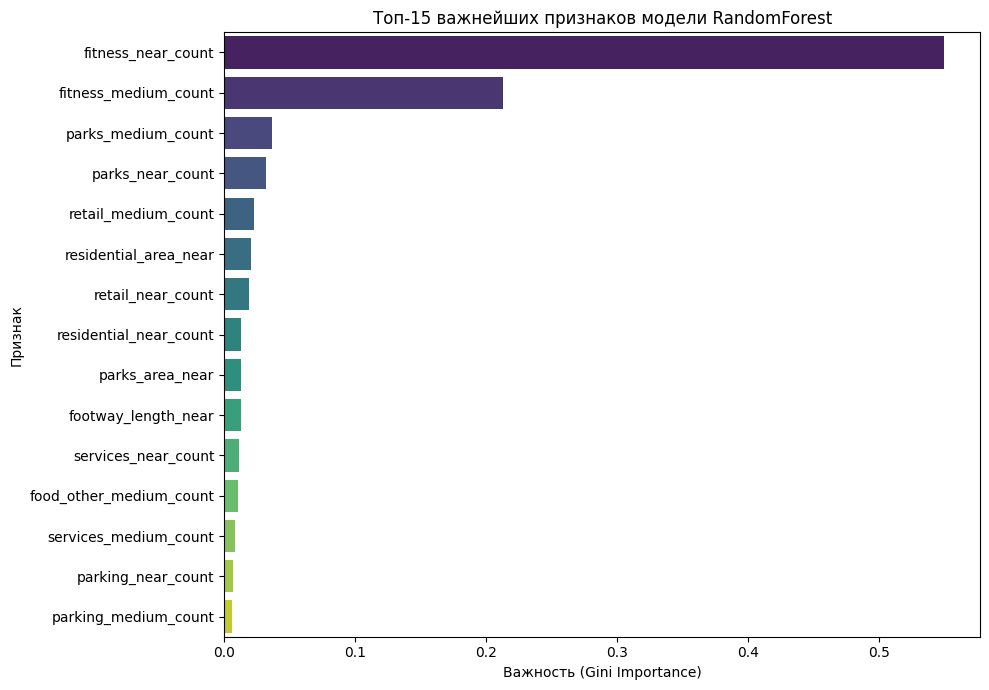

In [ ]:
# Визуализация важности признаков
plt.figure(figsize=(10, 7))
top_features_rf = rf_feature_importance.head(15)
sns.barplot(data=top_features_rf, x='Важность', y='Признак', palette='viridis')
plt.title('Топ-15 важнейших признаков модели RandomForest')
plt.xlabel('Важность (Gini Importance)')
plt.ylabel('Признак')
plt.tight_layout()
plt.show()

In [ ]:
# Инициализируем модель GradientBoostingClassifier
gb_model = GradientBoostingClassifier(
    n_estimators=100,       # Количество деревьев (этапов бустинга)
    learning_rate=0.1,      # Скорость обучения (влияет на вклад каждого дерева)
    max_depth=5,            # Максимальная глубина деревьев
    random_state=42
)

# Кросс-валидация для Gradient Boosting
print("Проведение кросс-валидации для GradientBoosting...")
cv_scores_gb = cross_val_score(gb_model, X_scaled, y, cv=5, scoring='roc_auc', n_jobs=-1)
print(f"  GradientBoosting CV ROC AUC: {cv_scores_gb.mean():.4f} ± {cv_scores_gb.std():.4f}")

Проведение кросс-валидации для GradientBoosting...
  GradientBoosting CV ROC AUC: 0.9990 ± 0.0012


In [ ]:
# Обучаем модель на ОБУЧАЮЩЕЙ выборке
print("Обучение GradientBoosting на обучающей выборке...")
gb_model.fit(X_train, y_train)

# Предсказания на ТЕСТОВОЙ выборке
gb_preds = gb_model.predict(X_test)
gb_proba = gb_model.predict_proba(X_test)[:, 1]

# Оценка на ТЕСТОВОЙ выборке
gb_accuracy = accuracy_score(y_test, gb_preds)
gb_roc_auc = roc_auc_score(y_test, gb_proba)

print(f"  GradientBoosting Test Accuracy: {gb_accuracy:.4f}")
print(f"  GradientBoosting Test ROC AUC: {gb_roc_auc:.4f}")
print("\n  Отчет о классификации GradientBoosting (на тестовой выборке):")
print(classification_report(y_test, gb_preds, target_names=['Нет фитнес-центра', 'Есть фитнес-центр']))

Обучение GradientBoosting на обучающей выборке...
  GradientBoosting Test Accuracy: 1.0000
  GradientBoosting Test ROC AUC: 1.0000

  Отчет о классификации GradientBoosting (на тестовой выборке):
                   precision    recall  f1-score   support

Нет фитнес-центра       1.00      1.00      1.00      1425
Есть фитнес-центр       1.00      1.00      1.00       547

         accuracy                           1.00      1972
        macro avg       1.00      1.00      1.00      1972
     weighted avg       1.00      1.00      1.00      1972



In [ ]:
# Важность признаков для Gradient Boosting
gb_feature_importance = pd.DataFrame({
    'Признак': model_feature_columns,
    'Важность': gb_model.feature_importances_
}).sort_values('Важность', ascending=False)

print("\n  Топ-15 важных признаков GradientBoosting:")
display(gb_feature_importance.head(15))


  Топ-15 важных признаков GradientBoosting:


,Признак,Важность
26,fitness_near_count,0.995469
18,residential_area_near,0.000925
14,parking_near_count,0.000600
5,retail_medium_count,0.000492
21,parks_area_near,0.000409
7,services_medium_count,0.000341
17,residential_medium_count,0.000298
4,retail_near_count,0.000260
15,parking_medium_count,0.000202
11,transport_stops_medium_count,0.000169


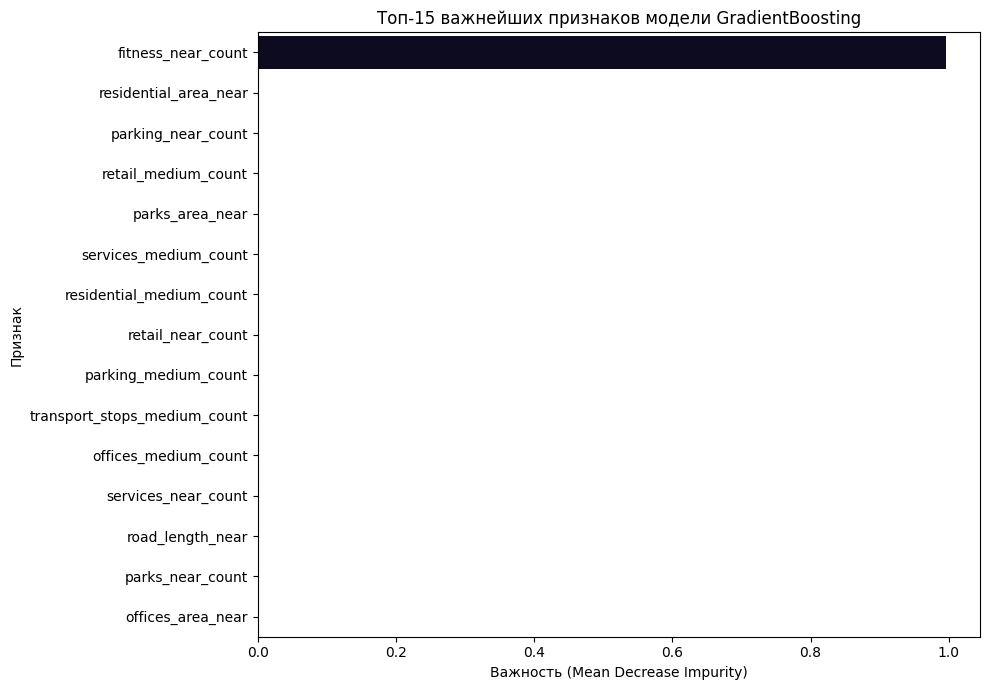

In [ ]:
# Визуализация важности признаков
plt.figure(figsize=(10, 7))
top_features_gb = gb_feature_importance.head(15)
sns.barplot(data=top_features_gb, x='Важность', y='Признак', palette='magma')
plt.title('Топ-15 важнейших признаков модели GradientBoosting')
plt.xlabel('Важность (Mean Decrease Impurity)')
plt.ylabel('Признак')
plt.tight_layout()
plt.show()

In [ ]:
# --- Шаг 3 (в рамках раздела 3): Сравнение моделей и выбор лучшей ---

# Сравниваем модели по ROC AUC на тестовой выборке
print("\n  Сравнение ROC AUC на тестовой выборке:")
models_comparison = pd.DataFrame({
    'Модель': ['RandomForest', 'GradientBoosting'],
    # Используем .get('gb_roc_auc', 0) на случай, если GB не обучился
    'ROC AUC (Test)': [rf_roc_auc, locals().get('gb_roc_auc', 0)],
    'ROC AUC (CV Mean)': [cv_scores_rf.mean(), cv_scores_gb.mean() if 'cv_scores_gb' in locals() else 0]
})
display(models_comparison.sort_values('ROC AUC (Test)', ascending=False))


  Сравнение ROC AUC на тестовой выборке:


,Модель,ROC AUC (Test),ROC AUC (CV Mean)
1,GradientBoosting,1.0,0.999012
0,RandomForest,1.0,0.999299


In [ ]:
# Выбираем лучшую модель на основе ROC AUC на тестовой выборке
# (Можно также ориентироваться на CV ROC AUC для большей надежности)
current_best_roc_auc = 0
if 'gb_roc_auc' in locals() and gb_roc_auc > rf_roc_auc:
    best_model = gb_model
    best_model_name = "GradientBoosting"
    best_roc_auc = gb_roc_auc
    best_feature_importance = gb_feature_importance
    print(f"\n  Лучшая модель по Test ROC AUC: {best_model_name} ({best_roc_auc:.4f})")
else:
    best_model = rf_model
    best_model_name = "RandomForest"
    best_roc_auc = rf_roc_auc
    best_feature_importance = rf_feature_importance
    print(f"\n  Лучшая модель по Test ROC AUC: {best_model_name} ({best_roc_auc:.4f})")

print("\n  Важные признаки лучшей модели:")
display(best_feature_importance.head(10))


  Лучшая модель по Test ROC AUC: GradientBoosting (1.0000)

  Важные признаки лучшей модели:


,Признак,Важность
26,fitness_near_count,0.995469
18,residential_area_near,0.000925
14,parking_near_count,0.000600
5,retail_medium_count,0.000492
21,parks_area_near,0.000409
7,services_medium_count,0.000341
17,residential_medium_count,0.000298
4,retail_near_count,0.000260
15,parking_medium_count,0.000202
11,transport_stops_medium_count,0.000169


In [ ]:
# Предсказываем ВЕРОЯТНОСТЬ привлекательности места расположения для ВСЕХ ячеек с помощью лучшей модели
print("\n  Предсказываем привлекательность места расположения для всех ячеек...")
# Используем predict_proba() для получения вероятности класса 1 (has_fitness_center=True)
# Применяем модель ко всем масштабированным данным X_scaled
environment_suitability_proba = best_model.predict_proba(X_scaled)[:, 1]
# Добавляем результат как новый столбец в GeoDataFrame
h3_gdf['environment_suitability'] = environment_suitability_proba

print("  Столбец 'environment_suitability' добавлен в h3_gdf.")
display(h3_gdf[['h3_index', 'has_fitness_center', 'environment_suitability']].head())


  Предсказываем привлекательность места расположения для всех ячеек...
  Столбец 'environment_suitability' добавлен в h3_gdf.


,h3_index,has_fitness_center,environment_suitability
0,8911aa7b41bffff,False,0.000013
1,8911aa4e95bffff,False,0.000013
2,8911aa45847ffff,False,0.000013
3,8911aa71b37ffff,False,0.000013
4,8911aa44e27ffff,True,0.999969


### **3.5. Пояснение**



*   Мы разделили данные на обучающую и тестовую выборки, сохраняя баланс классов.
*   Обучили две модели – RandomForest и GradientBoosting, предварительно оценив их потенциальную производительность с помощью кросс-валидации.
*   Оценили качество моделей на отложенной тестовой выборке по метрикам Accuracy, ROC AUC и с помощью Classification Report. ROC AUC является целевой метрикой для сравнения.
*   Проанализировали важность признаков для обеих моделей. Это дает ценную информацию о том, какие характеристики локации (например, близость офисов, магазинов, остановок, плотность жилой застройки) наиболее сильно связаны с присутствием фитнес-центров в данной области. Списки топ-признаков у RF и GB могут немного отличаться, но часто пересекаются.
*   Выбрали лучшую модель на основе ROC AUC на тестовой выборке.
*   Используя лучшую модель, мы рассчитали **вероятность привлекательности места расположения (`environment_suitability`)** для *каждой* ячейки H3 в нашем ROI. Это значение от 0 до 1, где 1 означает максимальную схожесть места расположения с теми местами, где уже существуют фитнес-центры (по мнению модели).



**Вывод по разделу:** Мы обучили несколько моделей и выбрали лучшую модель машинного обучения, которая научилась по характеристикам окружения предсказывать вероятность того, что среда в данной ячейке H3 является привлекательной для открытия фитнес-центра. Мы также определили наиболее значимые признаки этой "привлекательности".

## **Раздел 4. Улучшение модели с помощью кластеризации**


### **4.1. Кластеризация K-Means для выявления паттернов**


Иногда в данных существуют скрытые группы (кластеры) ячеек со схожими характеристиками, которые не очевидны для основной модели классификации. Добавление информации о принадлежности ячейки к тому или иному кластеру может улучшить качество предсказаний.

*   **K-Means:** Алгоритм кластеризации, который делит данные на K заранее заданных кластеров, минимизируя суммарное квадратичное отклонение точек от центров их кластеров (WCSS - Within-Cluster Sum of Squares).
*   **Метод локтя (Elbow Method):** Способ выбора оптимального числа кластеров K. Строится график зависимости WCSS от K. Оптимальным считается значение K в точке "изгиба" графика ("локоть"), после которой добавление новых кластеров уже не дает существенного уменьшения WCSS. Библиотека `kneed` помогает найти эту точку автоматически.
*   **PCA (Principal Component Analysis):** Метод снижения размерности. Мы используем его здесь не для моделирования, а для **визуализации** кластеров. Он преобразует многомерные данные в 2-3 измерения (главные компоненты), сохраняя при этом максимальное количество информации (дисперсии), что позволяет отобразить кластеры на плоскости.
*   **One-Hot Encoding (OHE):** Преобразование категориального признака (номер кластера) в набор бинарных признаков (0/1), по одному на каждый кластер. Это стандартный способ использования категориальных признаков в большинстве моделей ML.

**Идея:**
1.  Кластеризовать ячейки H3 на основе их масштабированных признаков места расположения (`X_scaled`).
2.  Создать новые бинарные признаки, указывающие на принадлежность ячейки к каждому кластеру.
3.  Добавить эти новые признаки к исходным (`X_scaled`).
4.  Переобучить нашу лучшую модель (RF или GB) на расширенном наборе признаков.
5.  Сравнить качество новой модели с исходной. Если есть *значительное* улучшение (например, ROC AUC вырос более чем на 0.01-0.05), использовать улучшенную модель. В противном случае, остаться с более простой исходной моделью.

### **4.2. Код: Определение K, кластеризация, PCA, OHE, переобучение модели**

  1. Определение оптимального K (метод локтя)...
    Оптимальное K найдено: 4


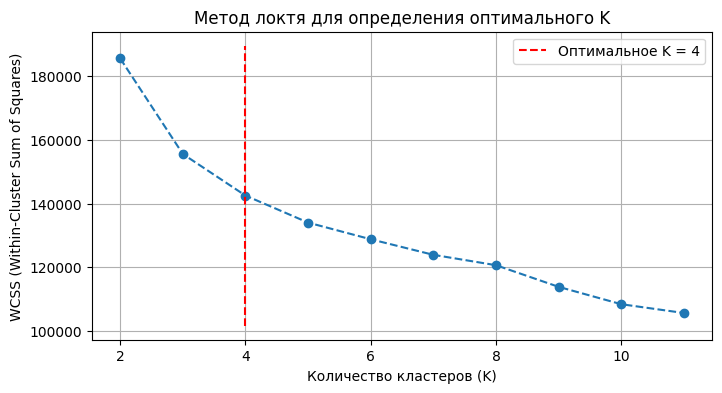

In [ ]:
# 1. Определяем оптимальное K с помощью метода локтя
print("  1. Определение оптимального K (метод локтя)...")
k_range = range(2, 12) # Диапазон K для проверки
wcss = [] # Список для хранения WCSS для каждого K
for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', max_iter=300, n_init='auto', random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_) # inertia_ атрибут содержит WCSS

# Визуализация метода локтя
plt.figure(figsize=(8, 4))
plt.plot(list(k_range), wcss, marker='o', linestyle='--')
plt.xlabel('Количество кластеров (K)')
plt.ylabel('WCSS (Within-Cluster Sum of Squares)')
plt.title('Метод локтя для определения оптимального K')
plt.grid(True)


# Автоматическое определение локтя с помощью kneed
# curve='convex', direction='decreasing' - базовые параметры для WCSS графика
try:
    kl = KneeLocator(list(k_range), wcss, curve='convex', direction='decreasing')
    optimal_k = kl.elbow
    if optimal_k is None: # Если локоть не найден автоматически
        print("    Локоть не найден автоматически, используем K=5 по умолчанию.")
        optimal_k = 5
    else:
        print(f"    Оптимальное K найдено: {optimal_k}")
        # Отмечаем найденный локоть на графике
        plt.vlines(optimal_k, plt.ylim()[0], plt.ylim()[1], linestyles='dashed', color='r', label=f'Оптимальное K = {optimal_k}')
        plt.legend()
except Exception as e:
    print(f"    Ошибка при поиске локтя ({e}), используем K=5 по умолчанию.")
    optimal_k = 5

plt.show()

In [ ]:
# 2. Обучаем KMeans с оптимальным K и получаем метки кластеров
print(f"  2. Обучение KMeans (K={optimal_k})...")
kmeans_final = KMeans(n_clusters=optimal_k, init='k-means++', max_iter=300, n_init='auto', random_state=42)
cluster_labels = kmeans_final.fit_predict(X_scaled) # Получаем номер кластера для каждой ячейки
h3_gdf['cluster_label'] = cluster_labels # Добавляем метки в GeoDataFrame (для анализа)
print(f"    Ячейки распределены по {optimal_k} кластерам.")
print(f"    Распределение по кластерам:\n{pd.Series(cluster_labels).value_counts().sort_index()}")

  2. Обучение KMeans (K=4)...
    Ячейки распределены по 4 кластерам.
    Распределение по кластерам:
0    3015
1    4142
2     490
3     239
Name: count, dtype: int64


  2.5. PCA-визуализация кластеров...


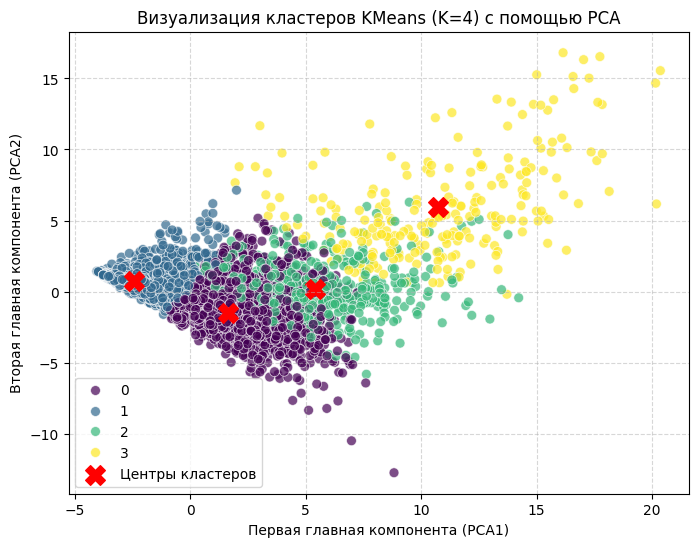

In [ ]:
# 2.5. Визуализация кластеров через PCA (для понимания)
print("  2.5. PCA-визуализация кластеров...")
pca = PCA(n_components=2, random_state=42) # Создаем PCA для 2 компонент
X_pca = pca.fit_transform(X_scaled) # Применяем PCA к масштабированным данным

plt.figure(figsize=(8, 6))
# Строим диаграмму рассеяния точек в пространстве 2 главных компонент, раскрашивая по кластерам
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=cluster_labels, palette='viridis', s=50, alpha=0.7, legend='full')
# Отображаем центры кластеров, также преобразованные PCA
centers_pca = pca.transform(kmeans_final.cluster_centers_)
plt.scatter(centers_pca[:, 0], centers_pca[:, 1], marker='X', s=200, c='red', label='Центры кластеров')
plt.xlabel('Первая главная компонента (PCA1)')
plt.ylabel('Вторая главная компонента (PCA2)')
plt.title(f'Визуализация кластеров KMeans (K={optimal_k}) с помощью PCA')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
# 3. One-Hot Encoding кластерных меток
print("  3. One-Hot Encoding кластеров...")
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore') # sparse=False возвращает плотный массив NumPy
# Преобразуем метки кластеров (вектор-столбец) в матрицу бинарных признаков
cluster_dummies = ohe.fit_transform(cluster_labels.reshape(-1, 1))
# Создаем имена для новых признаков
cluster_names = [f"Cluster_{i}" for i in range(cluster_dummies.shape[1])]
print(f"    Создано {len(cluster_names)} бинарных кластерных признаков.")

  3. One-Hot Encoding кластеров...
    Создано 4 бинарных кластерных признаков.


In [ ]:
# 4. Объединяем исходные масштабированные признаки с кластерными
# np.concatenate соединяет массивы по указанной оси (axis=1 - по столбцам)
X_with_cluster = np.concatenate([X_scaled, cluster_dummies], axis=1)
# Обновляем список имен всех признаков
features_with_cluster = model_feature_columns + cluster_names
print(f"    Общее количество признаков с учетом кластеров: {X_with_cluster.shape[1]}")

    Общее количество признаков с учетом кластеров: 35


In [ ]:
# 5. Переобучаем ЛУЧШУЮ модель (выбранную ранее) с новыми признаками
print(f"  5. Переобучение модели {best_model_name} с кластерными признаками...")
# Используем то же разделение train/test, что и раньше, но с новыми данными X_with_cluster
X_tr_clu, X_te_clu, y_tr_clu, y_te_clu = train_test_split(
    X_with_cluster, y, test_size=0.25, random_state=42, stratify=y
)

# Создаем новую модель того же типа с теми же параметрами, что и лучшая модель
if best_model_name == "RandomForest":
    params = rf_model.get_params() # Получаем параметры исходной RF модели
    model_cluster = RandomForestClassifier(**params) # Создаем новую RF с теми же параметрами
elif best_model_name == "GradientBoosting":
    params = gb_model.get_params() # Получаем параметры исходной GB модели
    model_cluster = GradientBoostingClassifier(**params) # Создаем новую GB с теми же параметрами
else: # На случай, если best_model_name не определен (хотя не должен)
    print("    Предупреждение: Не удалось определить тип лучшей модели, используется RandomForest по умолчанию.")
    model_cluster = RandomForestClassifier(random_state=42, class_weight='balanced')

# Обучаем новую модель на расширенных данных
model_cluster.fit(X_tr_clu, y_tr_clu)
# Оцениваем ROC AUC на тестовой выборке с расширенными признаками
roc_cluster = roc_auc_score(y_te_clu, model_cluster.predict_proba(X_te_clu)[:, 1])
print(f"    ROC AUC исходной модели ({best_model_name}): {best_roc_auc:.4f}")
print(f"    ROC AUC модели с кластерами: {roc_cluster:.4f}")

  5. Переобучение модели GradientBoosting с кластерными признаками...
    ROC AUC исходной модели (GradientBoosting): 1.0000
    ROC AUC модели с кластерами: 1.0000


In [ ]:
# 6. Обновляем модель, если улучшение ROC AUC ЗНАЧИТЕЛЬНОЕ
improvement_threshold = 0.01 # Порог улучшения ROC AUC (можно настроить)
if (roc_cluster - best_roc_auc) > improvement_threshold:
    print(f"  >>> Улучшение ROC AUC ({roc_cluster - best_roc_auc:.4f}) > порога ({improvement_threshold}). Принимаем модель с кластерами.")
    # Обновляем лучшую модель, ее имя, ROC AUC и данные для предсказания
    best_model = model_cluster
    best_model_name = best_model_name + "_with_Clusters"
    best_roc_auc = roc_cluster
    # Пересчитываем 'environment_suitability' с использованием улучшенной модели и расширенных признаков
    h3_gdf['environment_suitability'] = best_model.predict_proba(X_with_cluster)[:, 1]
    print(f"    Столбец 'environment_suitability' обновлен с учетом кластеров.")
else:
    print(f"  Улучшение ROC AUC ({(roc_cluster - best_roc_auc):.4f}) меньше порога ({improvement_threshold}). Используем исходную модель без кластеров.")
    # Ничего не меняем, оставляем исходную best_model и environment_suitability

  Улучшение ROC AUC (0.0000) меньше порога (0.01). Используем исходную модель без кластеров.


### **4.3. Пояснение**



*   Мы использовали метод локтя для выбора оптимального числа кластеров K.
*   Обучили модель KMeans и получили метки кластеров для каждой ячейки H3.
*   Визуализировали кластеры с помощью PCA, чтобы получить представление об их разделении в пространстве признаков.
*   Преобразовали метки кластеров в бинарные признаки с помощью One-Hot Encoding.
*   Объединили исходные признаки с новыми кластерными признаками.
*   Переобучили лучшую модель (выбранную на шаге 3.4) на этом расширенном наборе данных.
*   Сравнили ROC AUC новой модели с ROC AUC исходной модели. В данном случае, мы установили порог улучшения в 0.01. Если улучшение превышает порог, мы обновляем нашу `best_model` и пересчитываем `environment_suitability`. Если нет – оставляем исходную модель, так как добавление кластерных признаков не дало значимого прироста качества и только усложнило бы модель.



**Вывод по разделу:** Кластеризация может быть полезным инструментом для выявления скрытых структур в данных и потенциального улучшения основной модели. Однако важно оценивать, дает ли это *значимое* улучшение, чтобы избежать излишнего усложнения анализа. В нашем случае, код принимает решение автоматически на основе заданного порога.

## **Раздел 5. Расчет итогового потенциала локации**


### **5.1. Интегральная оценка потенциала (привлекательность места расположения vs конкуренция)**


До сих пор мы моделировали только **привлекательность места расположения (`environment_suitability`)**, основываясь на инфраструктуре и игнорируя существующих конкурентов. Однако для оценки **потенциала открытия нового фитнес-центра** необходимо учесть оба фактора:

1.  **Привлекательность места расположения:** Насколько окружение похоже на места, где фитнес-центры уже успешно работают (оценено нашей ML моделью).
2.  **Уровень конкуренции:** Сколько фитнес-центров уже есть поблизости. Высокая конкуренция снижает потенциал новой точки.

Мы рассчитаем итоговый **потенциал открытия (`opening_potential`)** как взвешенную сумму этих двух компонентов:

- `opening_potential = W_env * environment_suitability + W_comp * (1 - normalized_competition)`

Где:

*   `environment_suitability`: Рассчитанная ранее вероятность привлекательности места расположения (от 0 до 1).
*   `normalized_competition`: Уровень конкуренции, нормализованный к диапазону от 0 до 1. Мы используем количество конкурентов в *среднем* радиусе (`fitness_centers_medium_count`), деленное на максимальное количество конкурентов в среднем радиусе по всей территории (`max_competitors`). `(1 - normalized_competition)` дает "свободу от конкуренции" (1 - нет конкурентов, 0 - максимальная конкуренция).
*   `W_env`, `W_comp`: Веса, определяющие относительную важность привлекательности места расположения и отсутствия конкуренции. Сумма весов должна быть равна 1 (например, `W_env = 0.7`, `W_comp = 0.3`). Выбор весов зависит от бизнес-стратегии (что важнее: идеальное место с конкурентами или менее идеальное, но без них?).

**Категоризация потенциала:** Для удобства интерпретации и визуализации мы разделим непрерывное значение `opening_potential` на несколько категорий (например, "Низкий", "Средний", "Высокий") с помощью квантилей. Квантили делят распределение данных на равные части (например, 5 квантилей делят данные на 5 групп по 20% ячеек в каждой).

### **5.2. Расчет и категоризация потенциала**

In [ ]:
# --- Шаг 4 (в нумерации исходного скрипта): Расчет потенциала для открытия кофейни ---

# Находим максимальное количество конкурентов в среднем радиусе для нормализации
# Добавляем 1, чтобы избежать деления на ноль, если конкурентов нигде нет
max_competitors = h3_gdf['fitness_centers_medium_count'].max()
if max_competitors == 0:
    max_competitors = 1 # Избегаем деления на ноль

In [ ]:
# Настраиваемые веса для компонентов потенциала (сумма должна быть = 1)
ENV_WEIGHT = 0.7       # Вес привлекательности места расположения
COMPETITION_WEIGHT = 0.3  # Вес фактора (отсутствия) конкуренции

In [ ]:
# Рассчитываем нормализованный показатель конкуренции
h3_gdf['normalized_competition'] = h3_gdf['fitness_centers_medium_count'] / max_competitors

# Формула потенциала открытия нового фитнес-центра
h3_gdf['opening_potential'] = (
    ENV_WEIGHT * h3_gdf['environment_suitability'] +
    COMPETITION_WEIGHT * (1 - h3_gdf['normalized_competition'])
)

# Убеждаемся, что потенциал находится в пределах от 0 до 1
h3_gdf['opening_potential'] = h3_gdf['opening_potential'].clip(0, 1)

print(f"  Рассчитан 'opening_potential' с весами: Локация={ENV_WEIGHT}, Конкуренция={COMPETITION_WEIGHT}")
display(h3_gdf[['h3_index', 'environment_suitability', 'fitness_centers_medium_count', 'normalized_competition', 'opening_potential']].head())

  Рассчитан 'opening_potential' с весами: Локация=0.7, Конкуренция=0.3


,h3_index,environment_suitability,fitness_centers_medium_count,normalized_competition,opening_potential
0,8911aa7b41bffff,0.000013,0,0.000000,0.300009
1,8911aa4e95bffff,0.000013,0,0.000000,0.300009
2,8911aa45847ffff,0.000013,0,0.000000,0.300009
3,8911aa71b37ffff,0.000013,0,0.000000,0.300009
4,8911aa44e27ffff,0.999969,1,0.035714,0.989264


In [ ]:
# --- Категоризация потенциала ---
print("\n  Категоризация потенциала...")

# Определяем границы для категорий с помощью квантилей (например, 5 категорий по 20%)
# Используем .quantile([0.2, 0.4, 0.6, 0.8])
try:
    # Рассчитываем квантили
    quantiles = h3_gdf['opening_potential'].quantile([0.2, 0.4, 0.6, 0.8]).tolist()
    # Создаем границы бинов: 0, квантили, 1. Удаляем дубликаты и сортируем.
    bins = sorted(list(set([0] + quantiles + [1])))
    print(f"    Границы бинов для категорий: {bins}")

    # Определяем метки категорий в зависимости от количества уникальных границ
    num_bins = len(bins) - 1
    if num_bins <= 1:
        labels = ['Низкий']
    elif num_bins == 2:
        labels = ['Низкий', 'Высокий']
    elif num_bins == 3:
        labels = ['Низкий', 'Средний', 'Высокий']
    elif num_bins == 4:
        labels = ['Очень низкий', 'Низкий', 'Средний', 'Высокий']
    else: # 5 и более бинов
        labels = ['Очень низкий', 'Низкий', 'Средний', 'Высокий', 'Очень высокий']

    # Используем pd.cut для присвоения категорий на основе бинов
    h3_gdf['potential_category'] = pd.cut(
        h3_gdf['opening_potential'],
        bins=bins,
        labels=labels[:num_bins], # Используем нужное количество меток
        include_lowest=True,      # Включаем нижнюю границу (0)
        duplicates='drop'         # Удаляем дублирующиеся границы, если они есть
    )
    print(f"    Созданы категории: {labels[:num_bins]}")

except Exception as e:
    print(f"    Ошибка при категоризации: {e}. Категории не созданы.")
    h3_gdf['potential_category'] = 'N/A' # Присваиваем значение по умолчанию


  Категоризация потенциала...
    Границы бинов для категорий: [0, 0.3000091683895994, 0.300009169348528, 0.30000918162474133, 0.9571213963419885, 1]
    Созданы категории: ['Очень низкий', 'Низкий', 'Средний', 'Высокий', 'Очень высокий']



  Распределение потенциала по территории:
    Очень низкий: 1579 ячеек (20.0%)
    Низкий: 3013 ячеек (38.2%)
    Средний: 178 ячеек (2.3%)
    Высокий: 1555 ячеек (19.7%)
    Очень высокий: 1561 ячеек (19.8%)


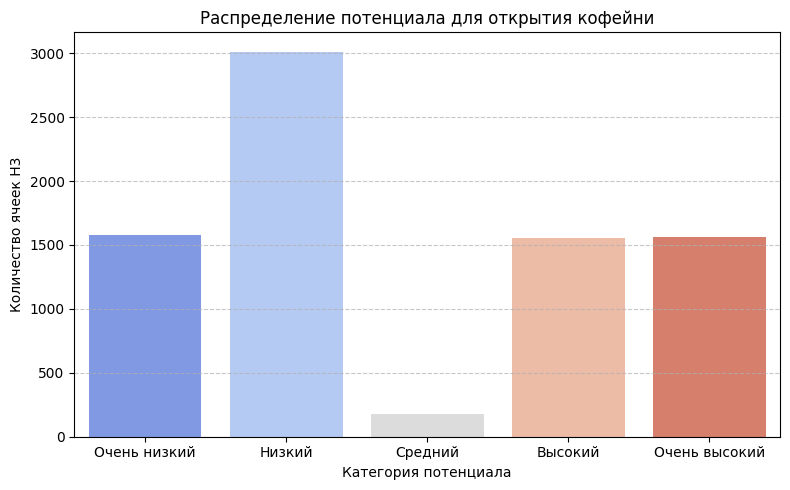

In [ ]:
# Анализ распределения потенциала по категориям
if 'potential_category' in h3_gdf.columns and h3_gdf['potential_category'].nunique() > 1:
    potential_distribution = h3_gdf['potential_category'].value_counts().sort_index()
    print("\n  Распределение потенциала по территории:")
    total_cells_count = len(h3_gdf)
    # Сортируем категории для логичного вывода
    ordered_labels = [l for l in ['Очень низкий', 'Низкий', 'Средний', 'Высокий', 'Очень высокий'] if l in potential_distribution.index]
    for category in ordered_labels:
        count = potential_distribution[category]
        percentage = count / total_cells_count * 100
        print(f"    {category}: {count} ячеек ({percentage:.1f}%)")

    # Визуализация распределения потенциала
    plt.figure(figsize=(8, 5))
    sns.countplot(data=h3_gdf, x='potential_category', order=ordered_labels, palette='coolwarm')
    plt.title('Распределение потенциала для открытия кофейни')
    plt.xlabel('Категория потенциала')
    plt.ylabel('Количество ячеек H3')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    # plt.xticks(rotation=45) # Раскомментировать, если метки накладываются
    plt.tight_layout()
    plt.show()
else:
    print("\n  Не удалось создать или визуализировать категории потенциала.")

### **5.3. Пояснение**



*   Мы рассчитали итоговый показатель `opening_potential` для каждой ячейки H3, комбинируя оценку привлекательности места расположения (`environment_suitability`) и уровень конкуренции (`fitness_centers_medium_count`). Веса `ENV_WEIGHT` и `COMPETITION_WEIGHT` позволяют настроить баланс между этими факторами.
*   Нормализация конкуренции (деление на максимум) привела ее к шкале от 0 до 1, сопоставимой с `environment_suitability`.
*   Итоговый потенциал был также ограничен диапазоном [0, 1].
*   Для наглядности мы разбили непрерывный потенциал на 5 категорий с помощью квантилей и функции `pd.cut`. Обработка дубликатов в квантилях важна на случай, если много ячеек имеют одинаковое значение потенциала.
*   Анализ и визуализация распределения ячеек по категориям потенциала дают общее представление о перспективности исследуемой территории.



**Вывод по разделу:** Мы получили интегральную оценку потенциала каждой ячейки H3 для открытия фитнес-центра, учитывающую как привлекательность самой локации, так и наличие конкурентов. Категоризация упрощает интерпретацию этих оценок.

## **Раздел 6. Визуализация и интерпретация результатов**



### **6.1. Интерактивная визуализация пространственных данных**

При решениии задач геоанализа особенно важно визуализировать значения на интерактивной карте.

Она позволяет:

*   Увидеть пространственные закономерности распределения потенциала.
*   Оценить расположение зон с высоким потенциалом относительно существующих фитнес-центров и объектов инфраструктуры.
*   Легко идентифицировать конкретные перспективные локации.



Мы будем использовать библиотеку `leafmap` (которая основана на `ipyleaflet` и `folium`), чтобы создать интерактивную карту со следующими слоями:

*   **Тепловая карта (Choropleth):** Гексагоны H3, окрашенные в зависимости от значения `opening_potential`. Удобно использовать цветовую схему от красного (низкий потенциал) к зеленому (высокий потенциал).
*   **Маркеры существующих фитнес-центров:** Позволяют видеть расположение конкурентов. Можно использовать кластеризацию маркеров (`MarkerCluster`) для областей с высокой плотностью.
*   **Маркеры рекомендуемых локаций:** Выделение ячеек с наивысшим потенциалом (например, топ-20), особенно тех, где нет конкурентов в непосредственной близости (`fitness_centers_near_count == 0`). Маркеры могут содержать всплывающие окна (popups) с подробной информацией о потенциале и характеристиках локации.

**Система координат:** Для отображения на веб-картах (как в `leafmap`) данные обычно должны быть в географической системе координат **WGS84 (EPSG:4326)**. Поэтому перед визуализацией мы преобразуем наш `h3_gdf` и `fitness_centers` обратно в эту систему с помощью метода `.to_crs("EPSG:4326")`.







### **6.2. Создание интерактивных карт с результатами**

Создадим основную карту с тепловой картой потенциала и маркерами, а затем отдельную карту для топ-локаций.

In [ ]:
# --- Шаг 5: Визуализация результатов на карте ---

# Преобразование координат в WGS84
h3_gdf_wgs84 = h3_gdf.to_crs("EPSG:4326")
fitness_centers_wgs84 = fitness_centers.to_crs("EPSG:4326") if hasattr(fitness_centers, 'to_crs') else fitness_centers

# Создание карты
map_center = [(bbox[1] + bbox[3]) / 2, (bbox[0] + bbox[2]) / 2]
potential_map = leafmap.Map(center=map_center, zoom=11, layers_control=True)

# Добавляем слой с потенциалами для открытия как тепловую карту
potential_map.add_data(
    h3_gdf_wgs84,
    column="opening_potential",
    cmap="RdYlGn",
    scheme="FisherJenks",
    k=15,
    legend_title="Потенциал для открытия фитнес-центра",
    layer_name="Потенциал (тепловая карта)",
    style={"stroke": True, "color": "#333333", "weight": 0.3, "fillOpacity": 0.7}
)

In [ ]:
# Добавляем маркеры существующих фитнес-центров (если они есть)
if not fitness_centers_wgs84.empty:
    fitness_centers_wgs84['name'] = fitness_centers_wgs84['name'].fillna('Фитнес-центр без названия')
    markers = []
    for idx, row in fitness_centers_wgs84.iterrows():
        if row.geometry and not row.geometry.is_empty:
            center = row.geometry.centroid.coords[0][::-1]  # (lat, lon)
            popup_content = f"<b>{row['name']}</b>"
            # Поля, характерные для фитнес-центров в OSM
            for field in ['leisure', 'amenity', 'sport', 'opening_hours']:
                if field in row and pd.notna(row[field]):
                    popup_content += f"<br>{field.capitalize()}: {row[field]}"
            markers.append(Marker(
                location=center,
                popup=HTML(popup_content),
                icon=AwesomeIcon(name='heartbeat', marker_color='red', icon_color='white'),
                tooltip=row['name']
            ))
    potential_map.add_layer(MarkerCluster(markers=markers))

In [ ]:
# --- Добавление маркеров для топ-локаций ---
# Находим топ-20 локаций с наибольшим потенциалом и без фитнес-центров поблизости
top_locations_wgs84 = h3_gdf_wgs84[h3_gdf_wgs84['fitness_centers_near_count'] == 0].sort_values(
    'opening_potential', ascending=False
).head(20)

# Создаем разные иконки для топ-локаций
top_potential_icon = AwesomeIcon(name='trophy', marker_color='darkgreen', icon_color='white')
potential_icon = AwesomeIcon(name='star', marker_color='green', icon_color='white')

# Добавляем маркеры рекомендуемых локаций
for i, (idx, row) in enumerate(top_locations_wgs84.iterrows()):
    if row.geometry and not row.geometry.is_empty:
        center = row.geometry.centroid.coords[0][::-1]  # (lat, lon)

        # Выбираем иконку
        current_icon = top_potential_icon if i < 3 else potential_icon

        # Создаем информативный popup
        popup_content = f"""
        <div style="min-width: 220px;">
            <h4 style="margin-top:0;">Рекомендуемая локация #{i+1}</h4>
            <div><b>Потенциал:</b> {row['opening_potential']:.3f}</div>
            <div><b>Привлекательность среды:</b> {row['environment_suitability']:.3f}</div>
            <div><b>Фитнес-центры в среднем радиусе:</b> {int(row['fitness_centers_medium_count'])}</div>
            <div><b>Категория потенциала:</b> {row['potential_category']}</div>
            <hr><h5>Инфраструктура поблизости:</h5><ul>
        """

        # Добавляем инфраструктурные показатели
        infra_fields = {
            'offices_near_count': 'Офисы',
            'residential_near_count': 'Жилые здания',
            'retail_near_count': 'Магазины',
            'transport_stops_near_count': 'Остановки транспорта',
            'parks_near_count': 'Парки',
            'footway_length_near': 'Пешеходные пути (м)'
        }

        for field, label in infra_fields.items():
            if field in row and pd.notna(row[field]):
                value = row[field]
                if 'length' in field:
                    popup_content += f"<li>{label}: {value:.1f} м</li>"
                else:
                    popup_content += f"<li>{label}: {int(value)}</li>"

        popup_content += "</ul></div>"

        potential_map.add_marker(
            location=center,
            popup=HTML(popup_content),
            icon=current_icon,
            tooltip=f"#{i+1} Потенциал: {row['opening_potential']:.3f}"
        )

# Отображаем итоговую карту потенциала
potential_map

Map(center=[55.737300000000005, 37.6316], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_…

In [ ]:
# --- Карта с фокусом на топ-K локациях ---
def visualize_top_locations(h3_gdf_vis, k=10, competition_filter=True):
    """Визуализирует топ-k локаций с наивысшим потенциалом для открытия фитнес-центра на отдельной карте"""
    print(f"\nСоздание карты для топ-{k} локаций...")
    # Убедимся, что данные в WGS84
    if h3_gdf_vis.crs != "EPSG:4326":
        h3_gdf_vis = h3_gdf_vis.to_crs("EPSG:4326")

    # Фильтруем по отсутствию фитнес-центров рядом, если competition_filter=True
    if competition_filter:
        filtered_gdf = h3_gdf_vis[h3_gdf_vis['fitness_centers_near_count'] == 0].copy()
        print(f"  (Фильтр: без фитнес-центров в ближнем радиусе)")
        if filtered_gdf.empty:
            print(f"  Предупреждение: Не найдено локаций без фитнес-центров поблизости. Показываем топ-{k} из всех.")
            filtered_gdf = h3_gdf_vis.copy()  # Если таких нет, берем из всех
    else:
        filtered_gdf = h3_gdf_vis.copy()

    # Сортируем и выбираем топ-k
    top_k_gdf = filtered_gdf.sort_values('opening_potential', ascending=False).head(k)

    if top_k_gdf.empty:
        print(f"  Не найдено локаций для отображения топ-{k}.")
        return None

    # Создание карты с центром по выбранным локациям
    try:
        bbox_top_k = top_k_gdf.total_bounds
        center_top_k = [(bbox_top_k[1] + bbox_top_k[3]) / 2, (bbox_top_k[0] + bbox_top_k[2]) / 2]
        top_map = leafmap.Map(center=center_top_k, zoom=12)
    except Exception as e:
        print(f"  Ошибка при расчете центра для карты топ-{k}: {e}. Используем центр основной карты.")
        top_map = leafmap.Map(center=map_center, zoom=14)

    # Добавляем гексагоны топ-k как слой с цветовой кодировкой по рангу
    top_k_gdf['rank'] = range(1, len(top_k_gdf) + 1)
    top_map.add_data(
        top_k_gdf,
        column="rank",
        cmap="RdYlGn_r",  # Зелёный для топ-1
        scheme="EqualInterval",
        k=len(top_k_gdf),
        legend_title="Ранг локации",
        layer_name=f"Топ-{k} локации (гексагоны)",
        style={"stroke": True, "color": "black", "weight": 1.5, "fillOpacity": 0.75}
    )

    # Добавляем маркеры с рангом и информацией
    print(f"  Добавление маркеров для топ-{k} локаций...")
    for i, (_, row) in enumerate(top_k_gdf.iterrows()):
        rank = row['rank']
        centroid = row.geometry.centroid
        center_latlon = (centroid.y, centroid.x)  # (lat, lon)

        # Создаем popup для маркера
        popup_html = f"""<div style="min-width:200px">
            <h4 style="margin-top:0; color: darkgreen;">Локация #{rank}</h4>
            <div><b>Потенциал:</b> {row['opening_potential']:.3f} ({row.get('potential_category', 'N/A')})</div>
            <div><b>Привлекательность среды:</b> {row['environment_suitability']:.3f}</div>
            <div><b>Фитнес-центры (средний радиус):</b> {int(row['fitness_centers_medium_count'])}</div>
            <div><b>Координаты:</b> {centroid.y:.6f}, {centroid.x:.6f}</div>
        </div>"""

        # Добавляем маркер
        top_map.add_marker(
            location=center_latlon,
            popup=HTML(popup_html),
            tooltip=f"Локация #{rank} (Потенциал: {row['opening_potential']:.3f})",
            icon=AwesomeIcon(name='heartbeat', marker_color='darkgreen', icon_color='white', spin=(rank <= 3)),
            name=f"Маркер #{rank}"
        )

    # Вывод координат топ-k локаций в консоль
    print(f"\n--- Топ-{k} локаций {'без фитнес-центров поблизости' if competition_filter else ''} ---")
    for i, (_, row) in enumerate(top_k_gdf.iterrows()):
        coords = row.geometry.centroid
        print(f"{i+1}. Координаты: {coords.y:.6f}, {coords.x:.6f} | Потенциал: {row.opening_potential:.3f} | Категория: {row.get('potential_category', 'N/A')} | H3 Индекс: {row.h3_index}")

    return top_map

# Визуализация топ-10 локаций без фитнес-центров поблизости и вывод координат
top_map_viz = visualize_top_locations(h3_gdf_wgs84, k=10, competition_filter=True)
if top_map_viz:
    print("\nОтображение карты топ-10 локаций...")
    display(top_map_viz)


Создание карты для топ-10 локаций...
  (Фильтр: без фитнес-центров в ближнем радиусе)
  Добавление маркеров для топ-10 локаций...

--- Топ-10 локаций без фитнес-центров поблизости ---
1. Координаты: 55.634041, 37.450816 | Потенциал: 0.303 | Категория: Высокий | H3 Индекс: 8911aa4e873ffff
2. Координаты: 55.776496, 37.463542 | Потенциал: 0.302 | Категория: Высокий | H3 Индекс: 8911aa44923ffff
3. Координаты: 55.636619, 37.453920 | Потенциал: 0.301 | Категория: Высокий | H3 Индекс: 8911aa4e877ffff
4. Координаты: 55.633751, 37.455944 | Потенциал: 0.300 | Категория: Высокий | H3 Индекс: 8911aa4e863ffff
5. Координаты: 55.827154, 37.590951 | Потенциал: 0.300 | Категория: Высокий | H3 Индекс: 8911aa718abffff
6. Координаты: 55.749896, 37.783777 | Потенциал: 0.300 | Категория: Высокий | H3 Индекс: 8911aa61273ffff
7. Координаты: 55.757870, 37.452031 | Потенциал: 0.300 | Категория: Высокий | H3 Индекс: 8911aa44b97ffff
8. Координаты: 55.726298, 37.523736 | Потенциал: 0.300 | Категория: Высокий | H3

Map(center=[np.float64(55.73045222878682), np.float64(37.61730703801483)], controls=(ZoomControl(options=['pos…

### **6.3. Пояснение**



*   Мы создали две интерактивные карты:
    1.  **Обзорная карта:** Показывает распределение потенциала успешности открытия фитнес-центра (`opening_potential`) по всей исследуемой территории с помощью окрашенных гексагонов (choropleth). На ней также отображены существующие фитнес-центры (белые чашки) и топ-20 рекомендуемых локаций без ближайших конкурентов (звезды/трофеи). Всплывающие окна маркеров содержат детальную информацию.
    2.  **Карта топ-локаций:** Фокусируется на K лучших локациях (по умолчанию K=10 и без ближайших конкурентов), отображая их гексагоны и маркеры с основной информацией. Координаты этих локаций также выводятся в текстовом виде.
*   Использование `leafmap` и `ipyleaflet` позволяет создавать насыщенные интерактивные визуализации прямо в среде выполнения кода.
*   Настройка `cmap` (цветовая схема), `scheme` (алгоритм классификации для раскраски), `style` (стили отображения), `Marker`, `AwesomeIcon`, `MarkerCluster` и `popup` (всплывающие окна с HTML) позволяет гибко кастомизировать внешний вид карты.
*   Функция `visualize_top_locations` инкапсулирует логику фильтрации, сортировки и отображения лучших локаций.



**Вывод по разделу:** Интерактивные карты являются важным результатом геоанализа. Они позволяют наглядно представить распределение потенциала, увидеть расположение конкурентов и детально изучить характеристики наиболее перспективных локаций, что существенно облегчает принятие решения об открытии новой точки.

## **Заключение**


### **Обобщение изученного материала**


В данном блокноте мы прошли полный цикл геомаркетингового анализа для определения оптимальной локации фитнес-центра:

1.  **Сбор данных:** Загрузили данные о существующих фитнес-центрах и разнообразных объектах инфраструктуры из OpenStreetMap для выбранной области интереса (ROI).
2.  **Предобработка:** Создали гексагональную сетку H3 и спроецировали все данные в метрическую систему координат.
3.  **Feature Engineering:** Рассчитали для каждой ячейки H3 набор пространственных признаков, характеризующих ее окружение (количество, площадь, длина объектов в ближнем и среднем радиусе).
4.  **Оценка привлекательности места расположения:** Обучили и сравнили модели машинного обучения (Random Forest, Gradient Boosting) для предсказания вероятности того, что среда в ячейке благоприятна для фитнес-центра (на основе расположения существующих). Проанализировали важность различных факторов места расположения, а также рассмотрели улучшение модели с помощью кластеризации.
5.  **Расчет потенциала потенциала успешности открытия фитнес-центра:** Разработали интегральный показатель потенциала успешности открытия фитнес-центра, учитывающий как привлекательность места расположения (предсказанную моделью), так и уровень конкуренции.
6.  **Визуализация:** Представили результаты на интерактивных картах, отобразив распределение потенциала, расположение конкурентов и выделив наиболее перспективные локации.

### **Рекомендации по развитию данной тематики при написании ВКР:**



*   **Другие источники данных:**
    *   **Демографические данные:** Плотность населения, возрастные группы, уровень дохода (если доступны).
    *   **Данные о пешеходном и автомобильном трафике:** Могут быть получены из специализированных сервисов или смоделированы.
    *   **Данные о коммерческой недвижимости:** Стоимость аренды, тип помещений.
    *   **Данные социальных сетей:** Чекины, отзывы о местах.
*   **Более сложные модели:**
    *   **Модели регрессии:** Предсказание не бинарного факта наличия фитнес-центра, а, например, потенциального оборота или количества посетителей (требует соответствующих данных для обучения).
    *   **Географически взвешенная регрессия (GWR):** Учитывает пространственную неоднородность – влияние факторов может меняться в разных частях города.
    *   **Модели глубокого обучения:** Для анализа спутниковых снимков или данных о мобильности.
*   **Продвинутый пространственный анализ:**
    *   **Анализ зон доступности (Isochrones):** Определение областей, из которых можно добраться до точки за определенное время пешком или на транспорте.
    *   **Сетевой анализ:** Расчет кратчайших путей, анализ связности графа дорог.
    *   **Анализ видимости (Viewshed analysis):** Оценка того, насколько точка видна с окружающих улиц.
*   **Автоматизация и развертывание:** Создание веб-приложения (например, с использованием Streamlit или Dash) для интерактивного выбора ROI и получения результатов анализа.

### **Возможные направления применения**









Описанный подход не ограничивается только фитнес-центрами. Его можно адаптировать для определения оптимальных локаций для широкого круга объектов:

*   Магазины розничной торговли (продуктовые, одежда, электроника).
*   Рестораны и другие точки общественного питания.
*   Аптеки, банки, салоны красоты.
*   Пункты выдачи заказов (ПВЗ).
*   Зарядные станции для электромобилей.
*   Объекты социальной инфраструктуры (детские сады, поликлиники – с учетом других критериев).
*   Банкоматы.

Основой является правильный подбор факторов (признаков), релевантных для конкретного типа бизнеса, и адаптация модели оценки потенциала.